<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/Lab%20Exp/CO4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Olivetti faces: 400 images, 4096 pixels each
From-scratch PCA took 51.0s

Variance ratio (mine)    : [0.23813 0.13994 0.07969 0.04998 0.0361 ]
Variance ratio (sklearn) : [0.23813 0.13994 0.07969 0.04998 0.0361 ]
Explained variance match : True
Eigenvectors match (up to sign): True


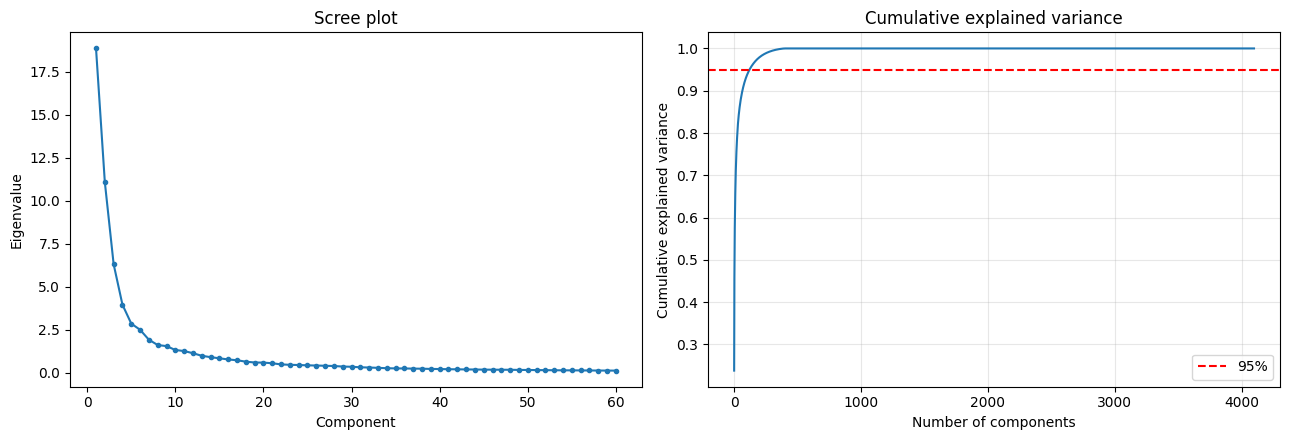


Components needed for 95% variance: 123 (out of 4096) -> 33.3x compression


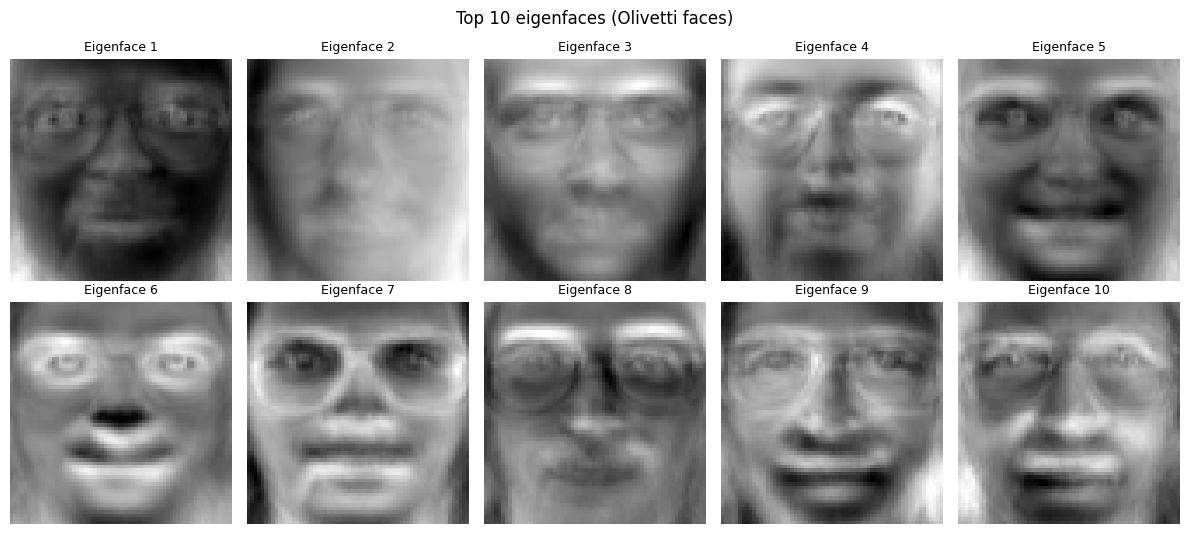

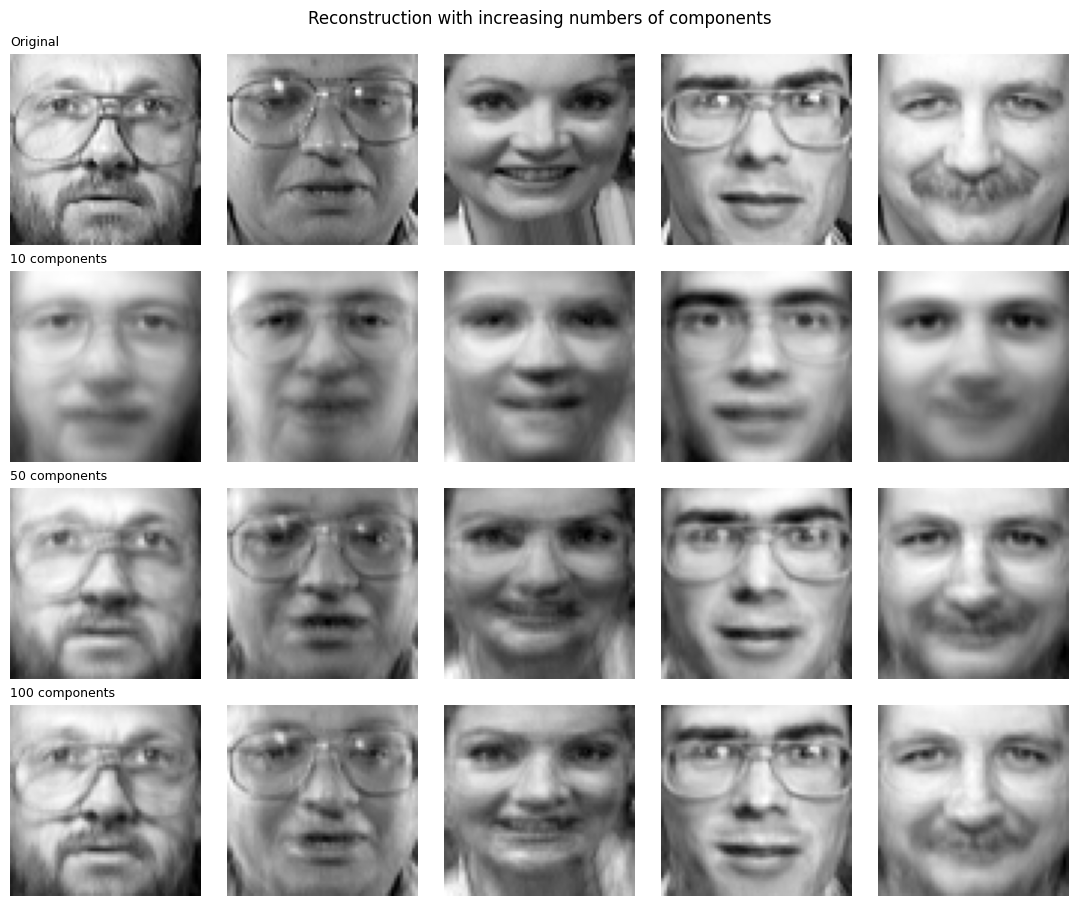

k =  10: reconstruction MSE = 0.00662, variance retained = 65.6%
k =  50: reconstruction MSE = 0.00243, variance retained = 87.4%
k = 100: reconstruction MSE = 0.00125, variance retained = 93.5%


In [1]:
"""Experiment 19: PCA and Explained Variance Analysis (Olivetti faces)"""
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits

np.random.seed(42)

# ---------------- Data: Olivetti faces (400 images, 64x64 = 4096 pixels) ----------------
try:
    from sklearn.datasets import fetch_olivetti_faces          # needs internet the first time
    X = fetch_olivetti_faces(shuffle=True, random_state=0).data
    IMG, NAME = (64, 64), "Olivetti faces"
except Exception as e:
    print("WARNING: could not load Olivetti faces (", type(e).__name__, ") -> using the digits dataset instead.")
    X = load_digits().data
    IMG, NAME = (8, 8), "Digits"
n, d = X.shape
print(f"{NAME}: {n} images, {d} pixels each")
KS = [10, 50, 100] if d > 1000 else [5, 15, 30]               # numbers of components to compare

# ---------------- Task 1: PCA from scratch (covariance + eigen-decomposition) ----------------
t0 = time.time()
mean = X.mean(axis=0)
Xc = X - mean                                                  # 1. centre the data
cov = np.cov(Xc, rowvar=False)                                 # 2. covariance matrix (d x d)
eigvals, eigvecs = np.linalg.eigh(cov)                         # 3. eigen-decomposition (symmetric matrix)
order = np.argsort(eigvals)[::-1]                              # 4. sort by decreasing eigenvalue
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
eigvals = np.clip(eigvals, 0, None)
print(f"From-scratch PCA took {time.time() - t0:.1f}s")

def project(Xc, k):    return Xc @ eigvecs[:, :k]              # 5. project onto top-k eigenvectors
def reconstruct(Xc, k):
    V = eigvecs[:, :k]
    return (Xc @ V) @ V.T + mean

# ---------------- Task 2: verify against scikit-learn ----------------
k_check = 20
skl = PCA(n_components=k_check, svd_solver="full").fit(X)
ratio_mine = eigvals / eigvals.sum()
print("\nVariance ratio (mine)    :", np.round(ratio_mine[:5], 5))
print("Variance ratio (sklearn) :", np.round(skl.explained_variance_ratio_[:5], 5))
print("Explained variance match :", np.allclose(ratio_mine[:k_check], skl.explained_variance_ratio_, atol=1e-6))
same_axes = [np.isclose(abs(eigvecs[:, i] @ skl.components_[i]), 1.0, atol=1e-4) for i in range(k_check)]
print("Eigenvectors match (up to sign):", all(same_axes))

# ---------------- Task 3: scree plot and cumulative explained variance ----------------
cum = np.cumsum(ratio_mine)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = min(60, len(eigvals))
ax[0].plot(range(1, m + 1), eigvals[:m], "o-", ms=3); ax[0].set_title("Scree plot")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Eigenvalue")
ax[1].plot(range(1, len(cum) + 1), cum); ax[1].axhline(0.95, color="r", ls="--", label="95%")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance")
ax[1].set_title("Cumulative explained variance"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------------- Task 4: components for 95% variance ----------------
k95 = int(np.argmax(cum >= 0.95) + 1)
print(f"\nComponents needed for 95% variance: {k95} (out of {d}) -> {d / k95:.1f}x compression")

# ---------------- Task 5: eigenfaces and reconstructions ----------------
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, a in enumerate(axes.ravel()):
    a.imshow(eigvecs[:, i].reshape(IMG), cmap="gray"); a.set_title(f"Eigenface {i+1}", fontsize=9); a.axis("off")
plt.suptitle(f"Top 10 eigenfaces ({NAME})"); plt.tight_layout(); plt.show()

show = 5
fig, axes = plt.subplots(1 + len(KS), show, figsize=(2.2 * show, 2.3 * (1 + len(KS))))
for j in range(show):
    axes[0, j].imshow(X[j].reshape(IMG), cmap="gray"); axes[0, j].axis("off")
    if j == 0: axes[0, j].set_title("Original", fontsize=9, loc="left")
    for r, k in enumerate(KS, start=1):
        rec = reconstruct(Xc[j:j + 1], k)[0]
        axes[r, j].imshow(rec.reshape(IMG), cmap="gray"); axes[r, j].axis("off")
        if j == 0: axes[r, j].set_title(f"{k} components", fontsize=9, loc="left")
plt.suptitle("Reconstruction with increasing numbers of components"); plt.tight_layout(); plt.show()
for k in KS:
    mse = np.mean((reconstruct(Xc, k) - X) ** 2)
    print(f"k = {k:3d}: reconstruction MSE = {mse:.5f}, variance retained = {cum[k-1]*100:.1f}%")

True latent dimension q = 3, true noise variance sigma^2 = 0.250

PPCA generative model:   x = W z + mu + eps
    z   ~ N(0, I_q)            latent variables (q < d)
    eps ~ N(0, sigma^2 I_d)    isotropic Gaussian noise
    => x ~ N(mu, W W^T + sigma^2 I)
Maximum-likelihood solution (Tipping & Bishop):
    sigma^2 = mean of the (d - q) smallest eigenvalues of the sample covariance
    W       = U_q (Lambda_q - sigma^2 I)^(1/2)
Ordinary PCA is the limit sigma^2 -> 0.

Estimated sigma^2 (closed-form PPCA)        : 0.2532
Estimated sigma^2 (sklearn PCA.noise_variance_): 0.2536
True sigma^2                                  : 0.2500

  k | PCA vs noisy  PPCA vs noisy | PCA vs clean  PPCA vs clean
  1 |       6.1787         6.3335 |       5.9954         6.1387
  2 |       1.9040         1.9476 |       1.7776         1.8128
  3 |       0.1582         0.1592 |       0.0926         0.0917
  4 |       0.1224         0.1495 |       0.1284         0.0924
  5 |       0.0893         0.1416 |      

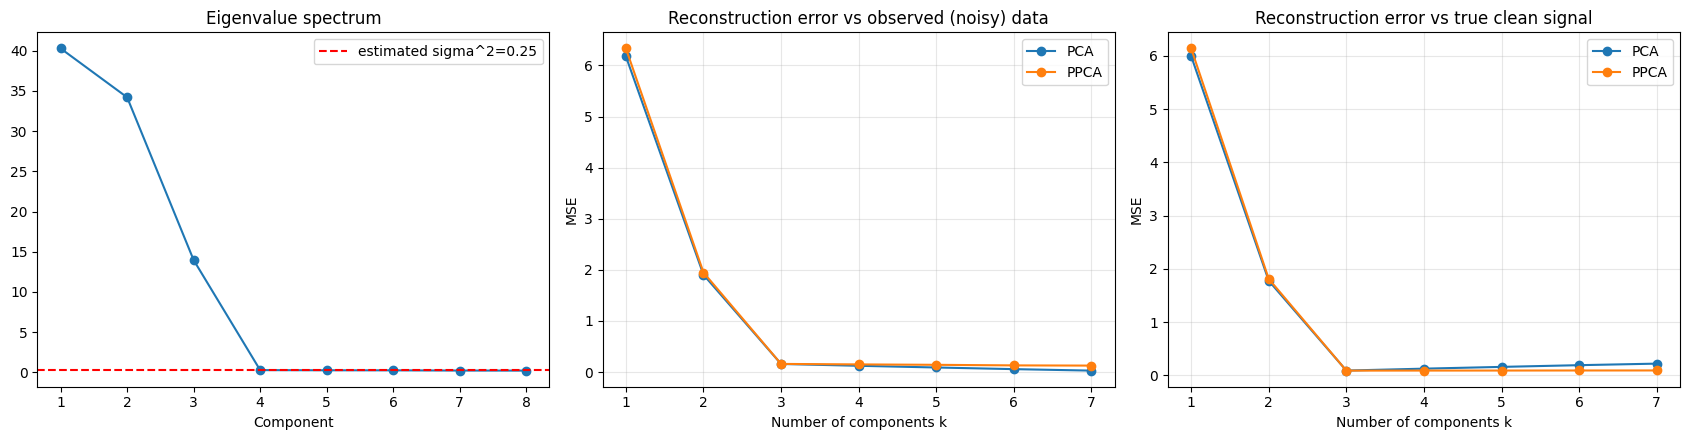


Generated 500 new samples; relative covariance difference vs real data = 0.149


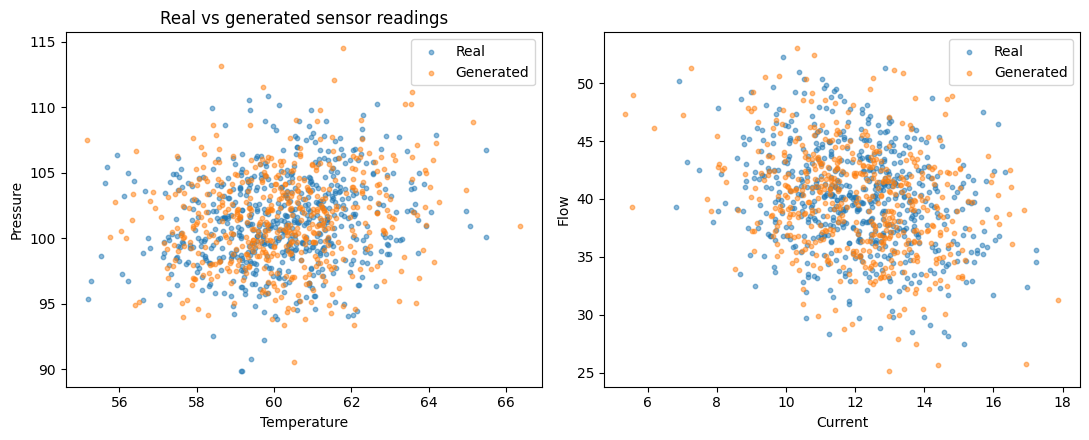

In [2]:
"""Experiment 20: Probabilistic PCA and Reconstruction Analysis (noisy sensor data)"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)

# ---------------- Data: 8 sensors driven by 3 hidden factors + Gaussian noise ----------------
sensors = ["Temperature", "Vibration", "Pressure", "Current", "Speed", "Voltage", "Flow", "Humidity"]
n, d, q_true, sigma_true = 600, 8, 3, 0.5
mu_true = np.array([60, 2.0, 101, 12, 1500, 230, 40, 55], dtype=float)
W_true = np.random.randn(d, q_true) * 2.0
Z = np.random.randn(n, q_true)
clean = Z @ W_true.T + mu_true                                   # noise-free signal
X = clean + np.random.normal(0, sigma_true, (n, d))              # observed readings
print(f"True latent dimension q = {q_true}, true noise variance sigma^2 = {sigma_true**2:.3f}")

# ---------------- Task 1: the PPCA generative model ----------------
print("""
PPCA generative model:   x = W z + mu + eps
    z   ~ N(0, I_q)            latent variables (q < d)
    eps ~ N(0, sigma^2 I_d)    isotropic Gaussian noise
    => x ~ N(mu, W W^T + sigma^2 I)
Maximum-likelihood solution (Tipping & Bishop):
    sigma^2 = mean of the (d - q) smallest eigenvalues of the sample covariance
    W       = U_q (Lambda_q - sigma^2 I)^(1/2)
Ordinary PCA is the limit sigma^2 -> 0.""")

# ---------------- Task 2 & 3: fit PPCA, estimate sigma^2 ----------------
mu_hat = X.mean(axis=0)
Xc = X - mu_hat
S = Xc.T @ Xc / n                                                # ML covariance (divide by n)
evals, evecs = np.linalg.eigh(S)
order = np.argsort(evals)[::-1]; evals, evecs = evals[order], evecs[:, order]

def fit_ppca(q):
    sigma2 = evals[q:].mean()
    W = evecs[:, :q] @ np.diag(np.sqrt(np.maximum(evals[:q] - sigma2, 0)))
    return W, sigma2

W3, sigma2_3 = fit_ppca(q_true)
skl = PCA(n_components=q_true).fit(X)
print(f"\nEstimated sigma^2 (closed-form PPCA)        : {sigma2_3:.4f}")
print(f"Estimated sigma^2 (sklearn PCA.noise_variance_): {skl.noise_variance_:.4f}")
print(f"True sigma^2                                  : {sigma_true**2:.4f}")

# ---------------- Task 4: reconstruction error vs number of components ----------------
def pca_reconstruct(k):
    V = evecs[:, :k]
    return (Xc @ V) @ V.T + mu_hat

def ppca_reconstruct(k):
    W, s2 = fit_ppca(k)
    M = W.T @ W + s2 * np.eye(k)
    Ez = Xc @ W @ np.linalg.inv(M)                               # posterior mean E[z | x] = M^-1 W^T (x - mu)
    return Ez @ W.T + mu_hat

ks = list(range(1, d))
err = {name: {"noisy": [], "clean": []} for name in ["PCA", "PPCA"]}
for k in ks:
    for name, fn in [("PCA", pca_reconstruct), ("PPCA", ppca_reconstruct)]:
        rec = fn(k)
        err[name]["noisy"].append(np.mean((rec - X) ** 2))        # error against observed data
        err[name]["clean"].append(np.mean((rec - clean) ** 2))    # error against the true noise-free signal
print(f"\n{'k':>3} | {'PCA vs noisy':>12} {'PPCA vs noisy':>14} | {'PCA vs clean':>12} {'PPCA vs clean':>14}")
for i, k in enumerate(ks):
    print(f"{k:3d} | {err['PCA']['noisy'][i]:12.4f} {err['PPCA']['noisy'][i]:14.4f} | "
          f"{err['PCA']['clean'][i]:12.4f} {err['PPCA']['clean'][i]:14.4f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(range(1, d + 1), evals, "o-"); ax[0].axhline(sigma2_3, color="r", ls="--", label=f"estimated sigma^2={sigma2_3:.2f}")
ax[0].set_title("Eigenvalue spectrum"); ax[0].set_xlabel("Component"); ax[0].legend()
for name in err:
    ax[1].plot(ks, err[name]["noisy"], "o-", label=name); ax[2].plot(ks, err[name]["clean"], "o-", label=name)
ax[1].set_title("Reconstruction error vs observed (noisy) data"); ax[2].set_title("Reconstruction error vs true clean signal")
for a in ax[1:]:
    a.set_xlabel("Number of components k"); a.set_ylabel("MSE"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------------- Task 5: generate new synthetic sensor samples ----------------
Z_new = np.random.randn(500, q_true)
X_new = Z_new @ W3.T + mu_hat + np.random.normal(0, np.sqrt(sigma2_3), (500, d))     # x = Wz + mu + eps
cov_gap = np.linalg.norm(np.cov(X_new, rowvar=False) - np.cov(X, rowvar=False)) / np.linalg.norm(np.cov(X, rowvar=False))
print(f"\nGenerated {len(X_new)} new samples; relative covariance difference vs real data = {cov_gap:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(X[:, 0], X[:, 2], s=10, alpha=0.5, label="Real"); ax[0].scatter(X_new[:, 0], X_new[:, 2], s=10, alpha=0.5, label="Generated")
ax[0].set_xlabel(sensors[0]); ax[0].set_ylabel(sensors[2]); ax[0].legend(); ax[0].set_title("Real vs generated sensor readings")
ax[1].scatter(X[:, 3], X[:, 6], s=10, alpha=0.5, label="Real"); ax[1].scatter(X_new[:, 3], X_new[:, 6], s=10, alpha=0.5, label="Generated")
ax[1].set_xlabel(sensors[3]); ax[1].set_ylabel(sensors[6]); ax[1].legend()
plt.tight_layout(); plt.show()

   Salary_fair  Benefits  Bonus_fair  Manager_support  Team_spirit  \
0            4         3           3                4            3   
1            4         4           4                4            3   
2            5         4           4                3            4   
3            3         4           3                2            3   
4            3         4           4                1            3   

   Communication  Career_growth  Training  Promotion_clarity  Workload_ok  
0              3              3         4                  4            4  
1              3              3         3                  3            3  
2              3              2         3                  3            3  
3              2              2         3                  3            3  
4              1              1         1                  2            2  

       Salary_fair  Benefits  Bonus_fair  Manager_support  Team_spirit  \
mean         3.06      3.08        3.05         

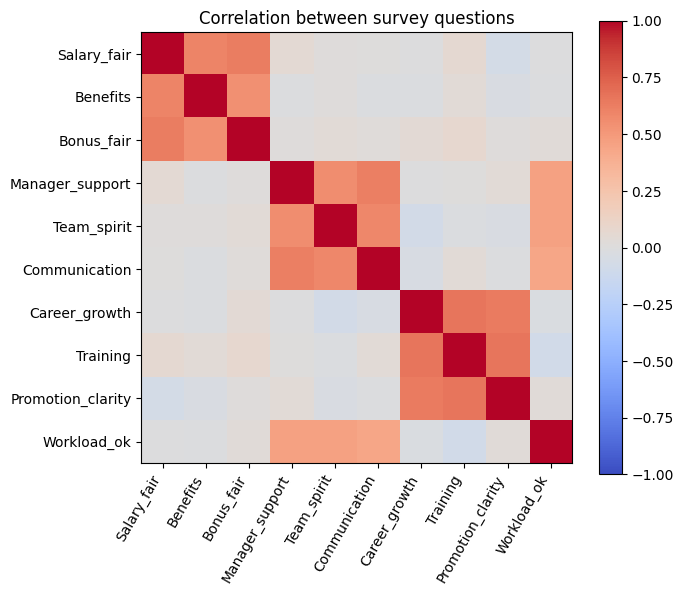

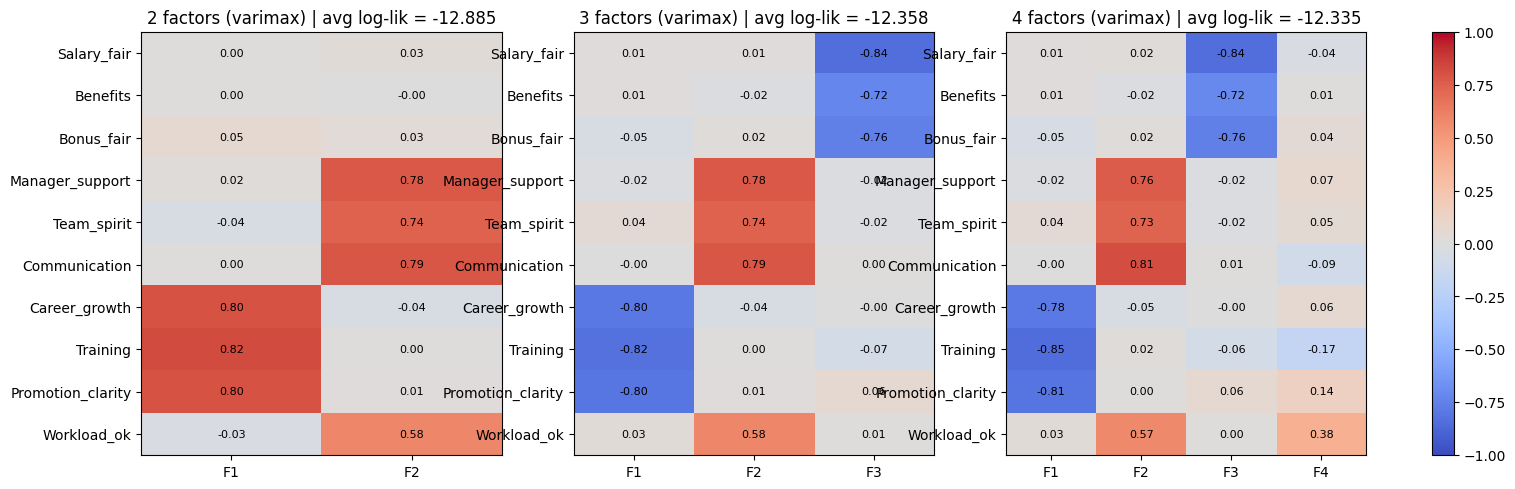

Average log-likelihood by number of factors: {2: -12.885, 3: -12.358, 4: -12.335}

Loadings (3 factors):
                      F1    F2    F3
Salary_fair        0.01  0.01 -0.84
Benefits           0.01 -0.02 -0.72
Bonus_fair        -0.05  0.02 -0.76
Manager_support   -0.02  0.78 -0.02
Team_spirit        0.04  0.74 -0.02
Communication     -0.00  0.79  0.00
Career_growth     -0.80 -0.04 -0.00
Training          -0.82  0.00 -0.07
Promotion_clarity -0.80  0.01  0.06
Workload_ok        0.03  0.58  0.01

Factor interpretation:
  F1: high-loading questions = ['Career_growth', 'Training', 'Promotion_clarity']  ->  'Growth'
  F2: high-loading questions = ['Manager_support', 'Team_spirit', 'Communication', 'Workload_ok']  ->  'Work Culture'
  F3: high-loading questions = ['Salary_fair', 'Benefits', 'Bonus_fair']  ->  'Compensation'

PCA loadings:
                     PC1   PC2   PC3
Salary_fair        0.08  0.26  0.84
Benefits           0.05  0.23  0.80
Bonus_fair         0.08  0.31  0.79
Manager

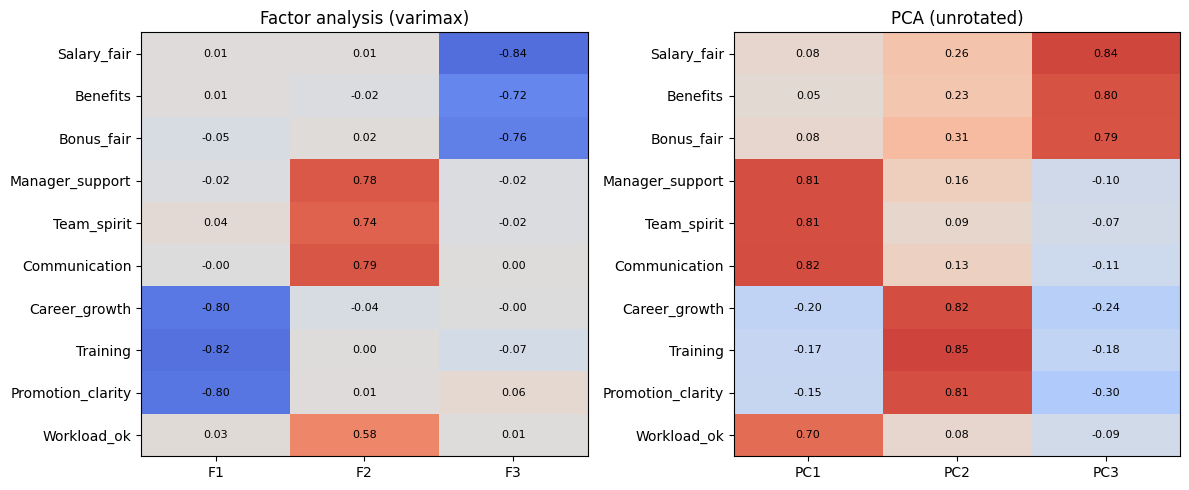


FA vs PCA: PCA finds components that maximise total variance (a data-compression tool); factor analysis models
each question as common factors + its own unique noise, so loadings are easier to interpret as hidden
constructs (e.g. 'Compensation'). Rotation (varimax) makes each question load strongly on one factor.


In [3]:
"""Experiment 21: Factor Analysis and Latent Factor Interpretation (employee survey)"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ---------------- Task 1: load / create survey data (300 employees, 10 Likert questions) ----------------
questions = ["Salary_fair", "Benefits", "Bonus_fair", "Manager_support", "Team_spirit",
             "Communication", "Career_growth", "Training", "Promotion_clarity", "Workload_ok"]
theme_of = dict(zip(questions, ["Compensation"] * 3 + ["Work Culture"] * 3 + ["Growth"] * 3 + ["Work Culture"]))
true_L = np.zeros((10, 3))                                         # hidden structure used to simulate answers
true_L[0:3, 0] = [0.9, 0.8, 0.85]; true_L[3:6, 1] = [0.85, 0.8, 0.75]
true_L[6:9, 2] = [0.9, 0.8, 0.85]; true_L[9, 1] = 0.5
F = np.random.randn(300, 3)
raw = F @ true_L.T + np.random.normal(0, 0.55, (300, 10))
df = pd.DataFrame(np.clip(np.round(3 + 0.9 * raw), 1, 5).astype(int), columns=questions)   # Likert 1-5
# To use real data:  df = pd.read_csv("survey.csv")
print(df.head()); print("\n", df.describe().round(2).loc[["mean", "std", "min", "max"]])

corr = df.corr()
plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(10), questions, rotation=60, ha="right"); plt.yticks(range(10), questions)
plt.title("Correlation between survey questions"); plt.tight_layout(); plt.show()

Xs = StandardScaler().fit_transform(df)

# ---------------- Tasks 2 & 3: FactorAnalysis with 2, 3, 4 factors + varimax ----------------
models = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, k in zip(axes, [2, 3, 4]):
    fa = FactorAnalysis(n_components=k, rotation="varimax", random_state=0).fit(Xs)
    models[k] = fa
    L = pd.DataFrame(fa.components_.T, index=questions, columns=[f"F{i+1}" for i in range(k)])
    im = ax.imshow(L, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(k)); ax.set_xticklabels(L.columns); ax.set_yticks(range(10)); ax.set_yticklabels(questions)
    for r in range(10):
        for c in range(k):
            ax.text(c, r, f"{L.iloc[r, c]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{k} factors (varimax) | avg log-lik = {fa.score(Xs):.3f}")
plt.colorbar(im, ax=axes, fraction=0.02); plt.show()
print("Average log-likelihood by number of factors:", {k: round(float(m.score(Xs)), 3) for k, m in models.items()})

# ---------------- Task 4: name the factors (3-factor model) ----------------
fa3 = models[3]
L3 = pd.DataFrame(fa3.components_.T, index=questions, columns=["F1", "F2", "F3"])
print("\nLoadings (3 factors):\n", L3.round(2))
print("\nFactor interpretation:")
for f in L3.columns:
    high = L3.index[np.abs(L3[f]) > 0.4].tolist()
    name = Counter(theme_of[q] for q in high).most_common(1)[0][0] if high else "?"
    print(f"  {f}: high-loading questions = {high}  ->  '{name}'")

# ---------------- Task 5: Factor analysis vs PCA ----------------
pca = PCA(n_components=3).fit(Xs)
pca_load = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=questions, columns=["PC1", "PC2", "PC3"])
print("\nPCA loadings:\n", pca_load.round(2))
print("PCA variance explained:", np.round(pca.explained_variance_ratio_, 3), "total =", round(pca.explained_variance_ratio_.sum(), 3))
print("FA noise variance (uniqueness) per question:\n", pd.Series(fa3.noise_variance_, index=questions).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, M, t in zip(ax, [L3, pca_load], ["Factor analysis (varimax)", "PCA (unrotated)"]):
    im = a.imshow(M, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    a.set_xticks(range(3)); a.set_xticklabels(M.columns); a.set_yticks(range(10)); a.set_yticklabels(questions); a.set_title(t)
    for r in range(10):
        for c in range(3):
            a.text(c, r, f"{M.iloc[r, c]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("""
FA vs PCA: PCA finds components that maximise total variance (a data-compression tool); factor analysis models
each question as common factors + its own unique noise, so loadings are easier to interpret as hidden
constructs (e.g. 'Compensation'). Rotation (varimax) makes each question load strongly on one factor.""")

Mixing matrix A:
 [[0.441 0.63  0.844]
 [0.093 0.119 0.818]
 [0.442 0.803 0.   ]]


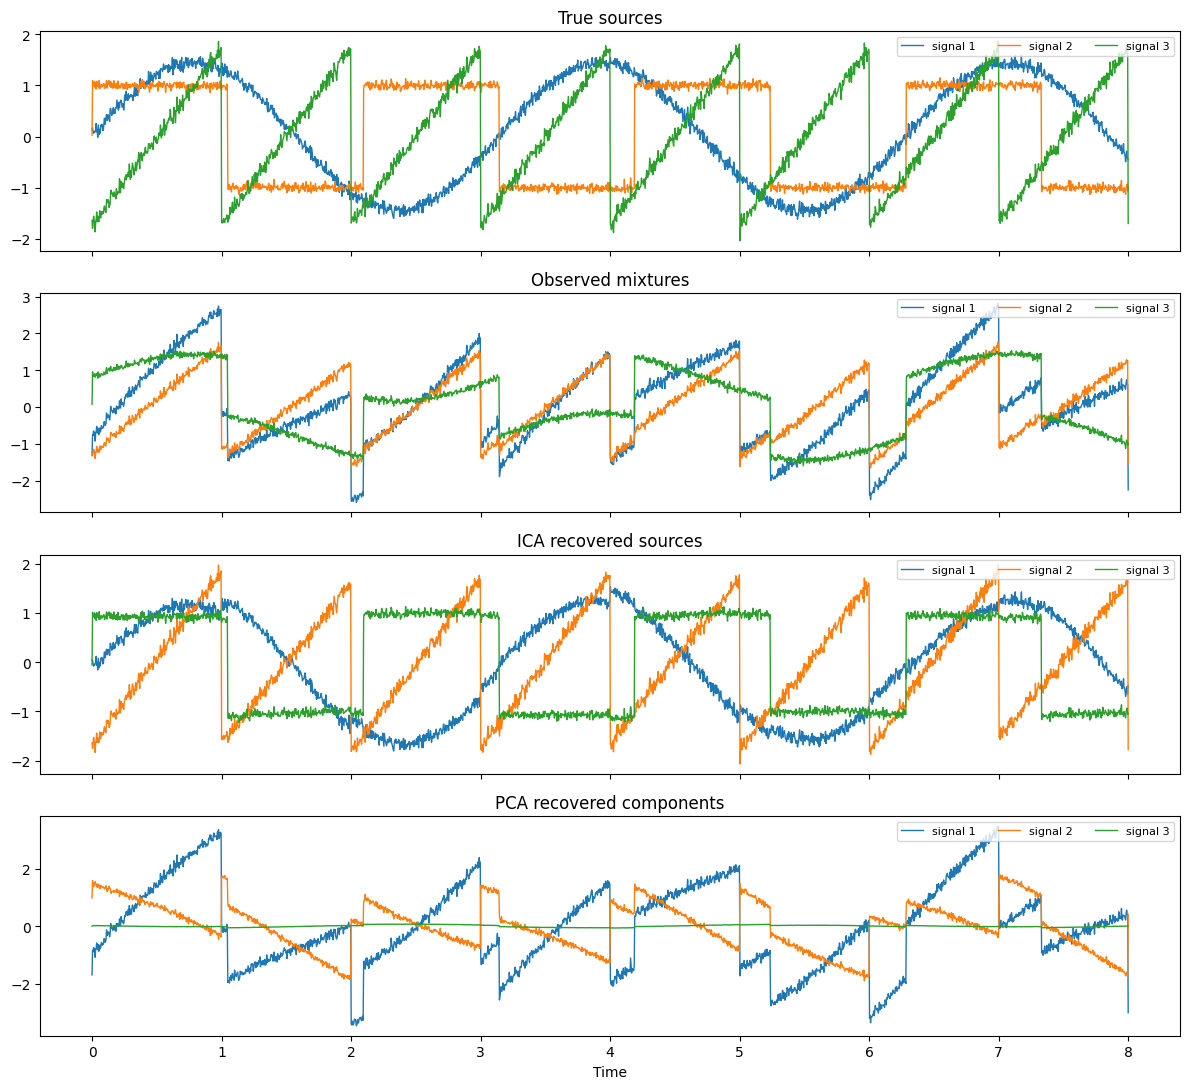


|Correlation| of true sources (rows) with ICA components (columns):
 [[0.997 0.056 0.058]
 [0.029 0.017 0.999]
 [0.071 0.997 0.039]]
|Correlation| of true sources (rows) with PCA components (columns):
 [[0.442 0.334 0.832]
 [0.618 0.626 0.476]
 [0.641 0.765 0.054]]

Source       ICA best |corr|   PCA best |corr|
Sine                  0.9967            0.8321
Square                0.9994            0.6258
Sawtooth              0.9968            0.7655
Mean                  0.9976            0.7411


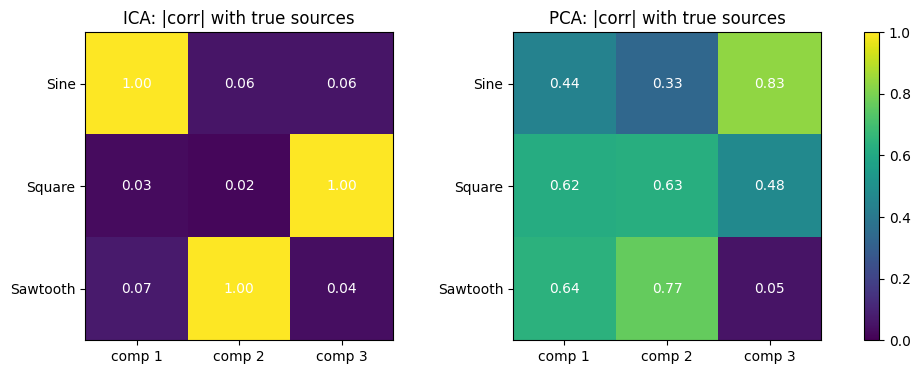


Conclusion: ICA exploits non-Gaussianity/independence and recovers each source almost perfectly; PCA only finds uncorrelated directions, so its components remain mixtures.


In [4]:
"""Experiment 22: Independent Component Analysis and Component Visualization (cocktail-party problem)"""
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import FastICA, PCA

np.random.seed(0)

# ---------------- Task 1: sources and mixing ----------------
n = 2000
time = np.linspace(0, 8, n)
s1 = np.sin(2 * time)                                  # sine
s2 = np.sign(np.sin(3 * time))                         # square wave
s3 = signal.sawtooth(2 * np.pi * time)                 # sawtooth
S = np.c_[s1, s2, s3]
S += 0.05 * np.random.normal(size=S.shape)             # small measurement noise
S /= S.std(axis=0)                                     # standardise the sources

A = np.random.rand(3, 3)                               # random mixing matrix
X = S @ A.T                                            # observed mixtures (3 "microphones")
print("Mixing matrix A:\n", np.round(A, 3))

# ---------------- Task 2: FastICA ----------------
ica = FastICA(n_components=3, whiten="unit-variance", random_state=0, max_iter=1000)
S_ica = ica.fit_transform(X)

# ---------------- Task 3: PCA on the same mixtures ----------------
pca = PCA(n_components=3)
S_pca = pca.fit_transform(X)

# ---------------- Task 4: plots ----------------
names = ["Sine", "Square", "Sawtooth"]
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for data, ax, title in zip([S, X, S_ica, S_pca], axes,
                           ["True sources", "Observed mixtures", "ICA recovered sources", "PCA recovered components"]):
    for i in range(3):
        ax.plot(time, data[:, i], lw=1, label=f"signal {i+1}")
    ax.set_title(title); ax.legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("Time")
plt.tight_layout(); plt.show()

# ---------------- Task 5: recovery quality ----------------
def match_quality(S_true, S_est):
    C = np.abs(np.corrcoef(S_true.T, S_est.T)[:3, 3:])        # |corr|: ICA/PCA ignore sign and order
    return C, C.max(axis=1)

C_ica, best_ica = match_quality(S, S_ica)
C_pca, best_pca = match_quality(S, S_pca)
print("\n|Correlation| of true sources (rows) with ICA components (columns):\n", np.round(C_ica, 3))
print("|Correlation| of true sources (rows) with PCA components (columns):\n", np.round(C_pca, 3))
print(f"\n{'Source':10}{'ICA best |corr|':>18}{'PCA best |corr|':>18}")
for nm, a, b in zip(names, best_ica, best_pca):
    print(f"{nm:10}{a:18.4f}{b:18.4f}")
print(f"{'Mean':10}{best_ica.mean():18.4f}{best_pca.mean():18.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, C, t in zip(ax, [C_ica, C_pca], ["ICA", "PCA"]):
    im = a.imshow(C, vmin=0, vmax=1, cmap="viridis")
    a.set_xticks(range(3)); a.set_xticklabels([f"comp {i+1}" for i in range(3)])
    a.set_yticks(range(3)); a.set_yticklabels(names); a.set_title(f"{t}: |corr| with true sources")
    for r in range(3):
        for c in range(3):
            a.text(c, r, f"{C[r, c]:.2f}", ha="center", va="center", color="w")
plt.colorbar(im, ax=ax, fraction=0.03); plt.show()
print("\nConclusion: ICA exploits non-Gaussianity/independence and recovers each source almost perfectly; "
      "PCA only finds uncorrelated directions, so its components remain mixtures.")

Nodes: ['Smoking', 'LungDisease', 'Pollution', 'Cough', 'XRay', 'Fatigue']
Edges: [('Smoking', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'XRay'), ('LungDisease', 'Fatigue'), ('Pollution', 'LungDisease')]

CPD of Smoking:
+--------------+-----+
| Smoking(no)  | 0.7 |
+--------------+-----+
| Smoking(yes) | 0.3 |
+--------------+-----+

CPD of Pollution:
+-----------------+-----+
| Pollution(low)  | 0.8 |
+-----------------+-----+
| Pollution(high) | 0.2 |
+-----------------+-----+

CPD of LungDisease:
+------------------+----------------+-----+----------------+-----------------+
| Smoking          | Smoking(no)    | ... | Smoking(yes)   | Smoking(yes)    |
+------------------+----------------+-----+----------------+-----------------+
| Pollution        | Pollution(low) | ... | Pollution(low) | Pollution(high) |
+------------------+----------------+-----+----------------+-----------------+
| LungDisease(no)  | 0.95           | ... | 0.7            | 0.5             |
+---

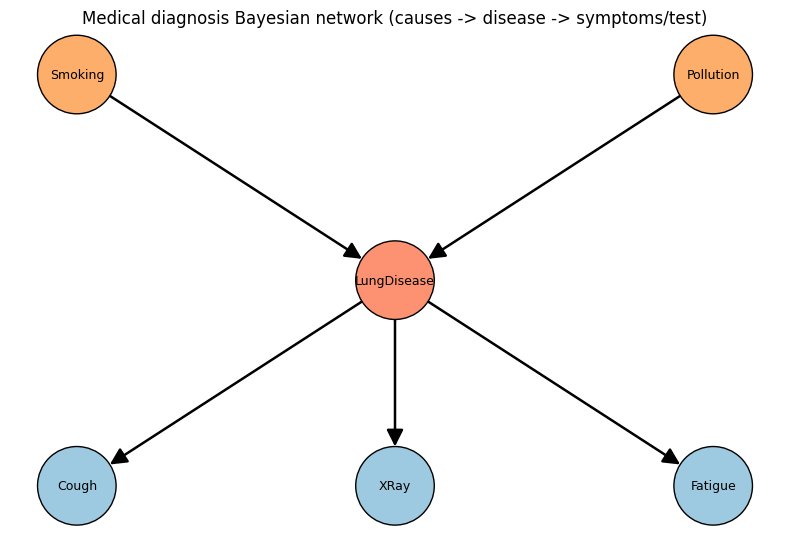


All conditional independencies in the network:
(Pollution ⟂ XRay | LungDisease)
(Fatigue ⟂ XRay | LungDisease)
(Pollution ⟂ Smoking)
(Cough ⟂ Fatigue | LungDisease)
(Cough ⟂ Pollution | LungDisease)
(Fatigue ⟂ Pollution | LungDisease)
(Cough ⟂ XRay | LungDisease)
(Smoking ⟂ XRay | LungDisease)
(Fatigue ⟂ Smoking | LungDisease)
(Cough ⟂ Smoking | LungDisease)

Local independencies (node independent of its non-descendants given its parents):
   (Smoking ⟂ Pollution)
   (Pollution ⟂ Smoking)
   (Cough ⟂ Fatigue, Pollution, Smoking, XRay | LungDisease)
   (XRay ⟂ Cough, Fatigue, Pollution, Smoking | LungDisease)
   (Fatigue ⟂ Cough, Pollution, Smoking, XRay | LungDisease)

Active trails (which nodes are connected / can influence each other):
  No evidence, from Smoking            : ['Cough', 'Fatigue', 'LungDisease', 'Smoking', 'XRay']
  Observe LungDisease, from Smoking    : ['Pollution', 'Smoking']
  Observe Cough, from Smoking          : ['Fatigue', 'LungDisease', 'Pollution', 'Smoking

In [6]:
!pip install -q pgmpy

"""Experiment 23: Bayesian Network Construction and Visualization (medical diagnosis)"""
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.factors.discrete import TabularCPD
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork      # pgmpy >= 1.0
except ImportError:
    from pgmpy.models import BayesianNetwork                                  # older pgmpy

# ---------------- Task 1: define the DAG ----------------
model = BayesianNetwork([
    ("Smoking", "LungDisease"),
    ("Pollution", "LungDisease"),
    ("LungDisease", "Cough"),
    ("LungDisease", "XRay"),
    ("LungDisease", "Fatigue"),
])
print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()))

# ---------------- Task 2: conditional probability distributions ----------------
# State order: row 0 = first state listed in state_names, row 1 = second state.
cpd_smoking = TabularCPD("Smoking", 2, [[0.7], [0.3]], state_names={"Smoking": ["no", "yes"]})
cpd_pollution = TabularCPD("Pollution", 2, [[0.8], [0.2]], state_names={"Pollution": ["low", "high"]})

# P(LungDisease | Smoking, Pollution): columns = (S,P) = (no,low), (no,high), (yes,low), (yes,high)
cpd_lung = TabularCPD(
    "LungDisease", 2,
    [[0.95, 0.85, 0.70, 0.50],          # LungDisease = no
     [0.05, 0.15, 0.30, 0.50]],         # LungDisease = yes
    evidence=["Smoking", "Pollution"], evidence_card=[2, 2],
    state_names={"LungDisease": ["no", "yes"], "Smoking": ["no", "yes"], "Pollution": ["low", "high"]})

cpd_cough = TabularCPD("Cough", 2, [[0.85, 0.20], [0.15, 0.80]], evidence=["LungDisease"], evidence_card=[2],
                       state_names={"Cough": ["no", "yes"], "LungDisease": ["no", "yes"]})
cpd_xray = TabularCPD("XRay", 2, [[0.95, 0.10], [0.05, 0.90]], evidence=["LungDisease"], evidence_card=[2],
                      state_names={"XRay": ["negative", "positive"], "LungDisease": ["no", "yes"]})
cpd_fatigue = TabularCPD("Fatigue", 2, [[0.80, 0.30], [0.20, 0.70]], evidence=["LungDisease"], evidence_card=[2],
                         state_names={"Fatigue": ["no", "yes"], "LungDisease": ["no", "yes"]})

model.add_cpds(cpd_smoking, cpd_pollution, cpd_lung, cpd_cough, cpd_xray, cpd_fatigue)
for cpd in model.get_cpds():
    print(f"\nCPD of {cpd.variable}:\n{cpd}")

# ---------------- Task 3: validate the model ----------------
print("\nmodel.check_model() ->", model.check_model())

# ---------------- Task 4: draw the network with NetworkX ----------------
G = nx.DiGraph(model.edges())
pos = {"Smoking": (0, 2), "Pollution": (2, 2), "LungDisease": (1, 1),
       "Cough": (0, 0), "XRay": (1, 0), "Fatigue": (2, 0)}
colors = {"Smoking": "#fdae6b", "Pollution": "#fdae6b", "LungDisease": "#fc9272",
          "Cough": "#9ecae1", "XRay": "#9ecae1", "Fatigue": "#9ecae1"}
plt.figure(figsize=(8, 5.5))
nx.draw_networkx(G, pos, node_color=[colors[n] for n in G.nodes], node_size=3200, font_size=9,
                 edgecolors="k", arrowsize=25, width=1.8)
plt.title("Medical diagnosis Bayesian network (causes -> disease -> symptoms/test)")
plt.axis("off"); plt.tight_layout(); plt.show()

# ---------------- Task 5: independencies and active trails ----------------
print("\nAll conditional independencies in the network:")
print(model.get_independencies())

print("\nLocal independencies (node independent of its non-descendants given its parents):")
for node in model.nodes():
    li = model.local_independencies(node)
    if str(li).strip():
        print("  ", li)

print("\nActive trails (which nodes are connected / can influence each other):")
print("  No evidence, from Smoking            :", sorted(model.active_trail_nodes("Smoking")["Smoking"]))
print("  Observe LungDisease, from Smoking    :", sorted(model.active_trail_nodes("Smoking", observed=["LungDisease"])["Smoking"]))
print("  Observe Cough, from Smoking          :", sorted(model.active_trail_nodes("Smoking", observed=["Cough"])["Smoking"]))
print("  Observe LungDisease, from Cough      :", sorted(model.active_trail_nodes("Cough", observed=["LungDisease"])["Cough"]))
print("\nInterpretation:")
print(" - Smoking and Pollution are independent a priori, but become dependent once LungDisease (or its effect Cough/XRay) is observed (collider).")
print(" - Cough, XRay and Fatigue are conditionally independent of each other given LungDisease (common cause).")

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


EXACT INFERENCE (Variable Elimination)
  P(Lung | no evidence)                            = 0.1510
  P(Lung | XRay=pos)                               = 0.7620
  P(Lung | XRay=pos, Cough=yes)                    = 0.9447
  P(Lung | XRay=pos, Cough=yes, Smoking=yes)       = 0.9802
  P(Lung | XRay=pos, Cough=yes, Smoking=no)        = 0.8784

=> Smoking changes the answer: same symptoms, but a smoker has a higher probability of lung disease.

Forward samples (first rows):
   Smoking LungDisease Pollution Cough      XRay Fatigue
0      no          no       low    no  negative      no
1     yes         yes       low   yes  positive     yes
2      no         yes       low   yes  positive     yes
3      no          no       low    no  negative      no
4      no         yes       low   yes  positive     yes
Rejection sampling returned 5000 samples consistent with the evidence {'XRay': 'positive', 'Cough': 'yes'}


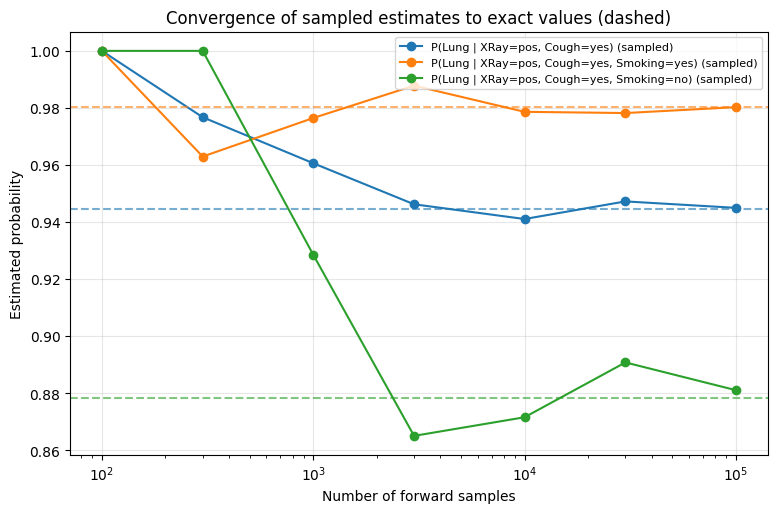


                                      Query  Exact (VE)  Forward sampling  Samples used  Rejection sampling  Abs error (forward)
                     P(Lung | no evidence)      0.1510            0.1505        100000                 NaN               0.0005
                        P(Lung | XRay=pos)      0.7620            0.7612         17799                 NaN               0.0008
             P(Lung | XRay=pos, Cough=yes)      0.9447            0.9450         11488               0.946               0.0003
P(Lung | XRay=pos, Cough=yes, Smoking=yes)      0.9802            0.9803          7401                 NaN               0.0001
 P(Lung | XRay=pos, Cough=yes, Smoking=no)      0.8784            0.8811          4087                 NaN               0.0027


In [7]:
"""Experiment 24: Graphical Model Sampling and Probabilistic Inference (medical network)"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.factors.discrete import TabularCPD, State
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

np.random.seed(0)

# ---------------- Same network as Experiment 23 ----------------
model = BayesianNetwork([("Smoking", "LungDisease"), ("Pollution", "LungDisease"),
                         ("LungDisease", "Cough"), ("LungDisease", "XRay"), ("LungDisease", "Fatigue")])
model.add_cpds(
    TabularCPD("Smoking", 2, [[0.7], [0.3]], state_names={"Smoking": ["no", "yes"]}),
    TabularCPD("Pollution", 2, [[0.8], [0.2]], state_names={"Pollution": ["low", "high"]}),
    TabularCPD("LungDisease", 2, [[0.95, 0.85, 0.70, 0.50], [0.05, 0.15, 0.30, 0.50]],
               evidence=["Smoking", "Pollution"], evidence_card=[2, 2],
               state_names={"LungDisease": ["no", "yes"], "Smoking": ["no", "yes"], "Pollution": ["low", "high"]}),
    TabularCPD("Cough", 2, [[0.85, 0.20], [0.15, 0.80]], evidence=["LungDisease"], evidence_card=[2],
               state_names={"Cough": ["no", "yes"], "LungDisease": ["no", "yes"]}),
    TabularCPD("XRay", 2, [[0.95, 0.10], [0.05, 0.90]], evidence=["LungDisease"], evidence_card=[2],
               state_names={"XRay": ["negative", "positive"], "LungDisease": ["no", "yes"]}),
    TabularCPD("Fatigue", 2, [[0.80, 0.30], [0.20, 0.70]], evidence=["LungDisease"], evidence_card=[2],
               state_names={"Fatigue": ["no", "yes"], "LungDisease": ["no", "yes"]}))
assert model.check_model()

# ---------------- Task 1: exact inference (Variable Elimination) ----------------
infer = VariableElimination(model)
queries = {
    "P(Lung | no evidence)":                         {},
    "P(Lung | XRay=pos)":                            {"XRay": "positive"},
    "P(Lung | XRay=pos, Cough=yes)":                 {"XRay": "positive", "Cough": "yes"},
    "P(Lung | XRay=pos, Cough=yes, Smoking=yes)":    {"XRay": "positive", "Cough": "yes", "Smoking": "yes"},
    "P(Lung | XRay=pos, Cough=yes, Smoking=no)":     {"XRay": "positive", "Cough": "yes", "Smoking": "no"},
}
exact = {}
print("EXACT INFERENCE (Variable Elimination)")
for name, ev in queries.items():
    q = infer.query(["LungDisease"], evidence=ev, show_progress=False)
    exact[name] = float(q.get_value(LungDisease="yes"))
    print(f"  {name:48s} = {exact[name]:.4f}")
print("\n=> Smoking changes the answer: same symptoms, but a smoker has a higher probability of lung disease.")

# ---------------- Task 2: forward sampling and rejection sampling ----------------
sampler = BayesianModelSampling(model)
N = 100_000
fwd = sampler.forward_sample(size=N, seed=1, show_progress=False)
print("\nForward samples (first rows):\n", fwd.head())

ev_main = {"XRay": "positive", "Cough": "yes"}
rej = sampler.rejection_sample(evidence=[State(k, v) for k, v in ev_main.items()],
                               size=5000, seed=2, show_progress=False)
print(f"Rejection sampling returned {len(rej)} samples consistent with the evidence {ev_main}")

# ---------------- Task 3: estimate queries from samples with Pandas ----------------
def estimate(df, evidence):
    sub = df
    for var, val in evidence.items():
        sub = sub[sub[var] == val]
    return (sub["LungDisease"] == "yes").mean() if len(sub) > 0 else np.nan, len(sub)

# ---------------- Task 4: convergence with sample size ----------------
sizes = [100, 300, 1000, 3000, 10000, 30000, 100000]
plt.figure(figsize=(9, 5.5))
curve_queries = ["P(Lung | XRay=pos, Cough=yes)", "P(Lung | XRay=pos, Cough=yes, Smoking=yes)",
                 "P(Lung | XRay=pos, Cough=yes, Smoking=no)"]
for name in curve_queries:
    ests = [estimate(fwd.iloc[:s], queries[name])[0] for s in sizes]
    line, = plt.plot(sizes, ests, "o-", label=f"{name} (sampled)")
    plt.axhline(exact[name], color=line.get_color(), ls="--", alpha=0.6)
plt.xscale("log"); plt.xlabel("Number of forward samples"); plt.ylabel("Estimated probability")
plt.title("Convergence of sampled estimates to exact values (dashed)"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

# ---------------- Task 5: exact vs approximate table ----------------
rows = []
for name, ev in queries.items():
    est_f, n_f = estimate(fwd, ev)
    row = {"Query": name, "Exact (VE)": exact[name], "Forward sampling": est_f, "Samples used": n_f}
    if ev == ev_main:                                            # rejection sampling was run for this evidence
        row["Rejection sampling"] = (rej["LungDisease"] == "yes").mean()
    rows.append(row)
table = pd.DataFrame(rows)
table["Abs error (forward)"] = (table["Exact (VE)"] - table["Forward sampling"]).abs()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
print("\n", table.round(4).to_string(index=False))